# Olist: Barplots y Pie Charts

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")

# 1 Categorías de productos
Utilizando la tabla de productos, determina cuántos productos existen en cada categoría.

Construye una gráfica de barras que muestre las categorías con mayor cantidad de productos.

Pregunta: ¿Qué categorías tienen mayor presencia en el catálogo de Olist?

Categorías como: "cama_mesa_banho", "esporte_lazer", "moveis_decoracao", "beleza_saude", "utilidades_domesticas"

Requisitos:
* Ordena las categorías de mayor a menor.
* Agrega un título.
* Etiqueta correctamente los ejes.
* Utiliza un color para las barras.

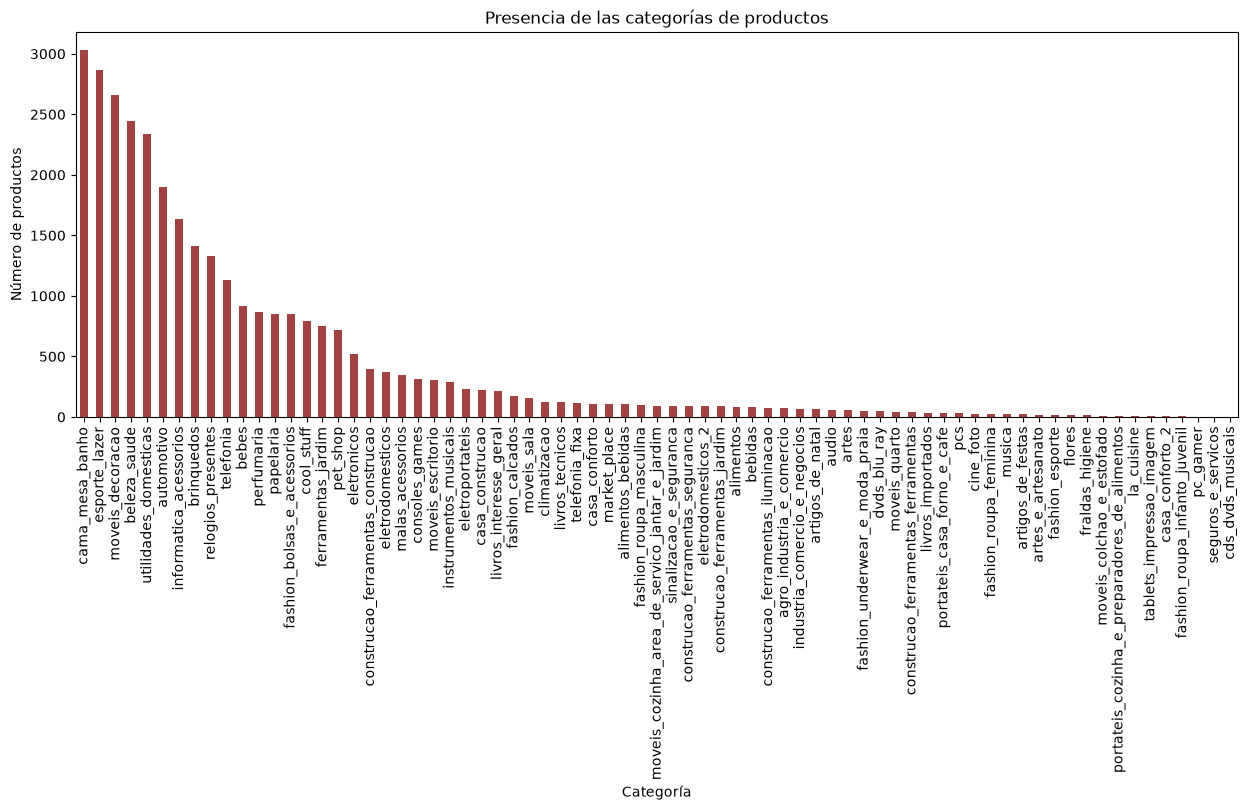

In [2]:
#1
df_1 = products.groupby("product_category_name")["product_id"].count().sort_values(ascending=False)
fig, ax1 = plt.subplots(figsize =(15,5))
df_1.plot(kind = "bar",
          color = "#a34242",
          title = "Presencia de las categorías de productos",
          xlabel = "Categoría",
          ylabel = "Número de productos"
)
plt.show()

# 2 Las 10 categorías principales
La cantidad de categorías de Olist puede hacer que una gráfica sea difícil de leer.

Construye una gráfica de barras mostrando únicamente las 10 categorías con mayor número de productos.

Pregunta: ¿Cuáles son las categorías que tienen mayor presencia en el catálogo?


Requisitos:
* Utiliza barras horizontales si consideras que facilitan la lectura.
* Ordena los resultados.
* Incluye título y etiquetas.

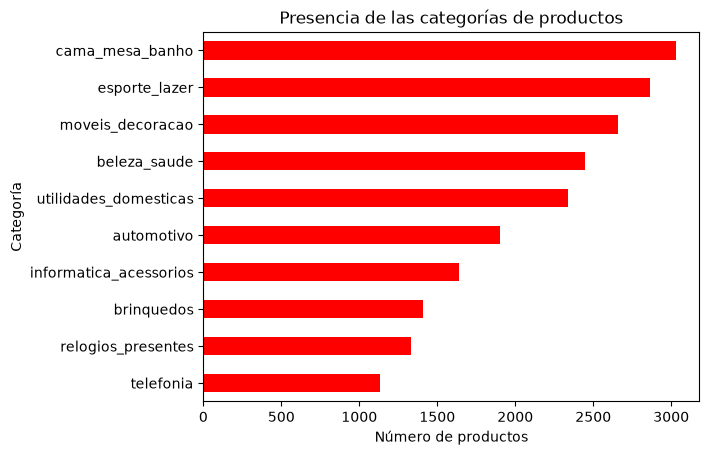

In [3]:
#2
df_2 = df_1.head(10).sort_values(ascending = True)
df_2.plot(kind = "barh",
          color = "red",
          title = "Presencia de las categorías de productos",
          xlabel = "Número de productos",
          ylabel = "Categoría"
)
plt.show()

# 3 Distribución de productos
Construye un pie chart que muestre cómo se distribuyen los productos entre las categorías.

Para evitar una gráfica ilegible, utiliza solamente las 5 categorías con mayor número de productos y agrupa todas las demás como "Otros".

Pregunta: ¿Qué proporción del catálogo está concentrada en las principales categorías?

Requisitos:
* Mostrar porcentajes.
* Etiquetar las categorías.
* Agregar un título.
* Utilizar colores diferentes.

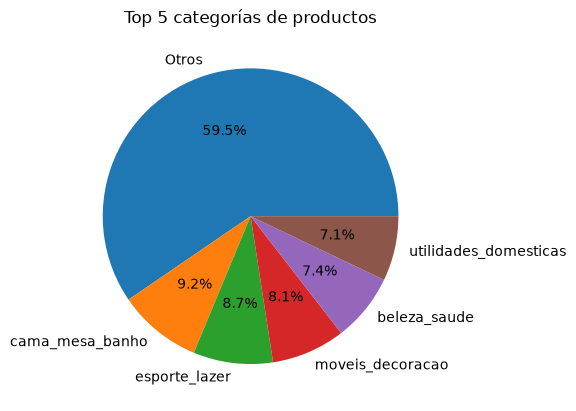

In [4]:
#3
df_3 = products
top5 = ["cama_mesa_banho", "esporte_lazer", "moveis_decoracao", "beleza_saude", "utilidades_domesticas"]
def top(x):
    if x in top5:
        return x
    else:
        return "Otros"

df_3["top5"] = df_3["product_category_name"].apply(top)
df_3 = df_3.groupby("top5")["product_id"].count().sort_values(ascending=False)

df_3

df_3.plot(kind = "pie",
          autopct = "%1.1f%%",
          title = "Top 5 categorías de productos"
)
plt.show()

# 4 Clientes por estado
Utilizando la información de los clientes, determina cuántos clientes existen en cada estado de Brasil.

Construye una gráfica de barras con los estados ordenados de mayor a menor cantidad de clientes.

Pregunta: ¿Qué estados concentran la mayor cantidad de clientes?

Estados como SP, RJ, MG, RS, PR, etc.

Requisitos:
* Mostrar todos los estados.
* Ordenar de mayor a menor.
* Utilizar barras horizontales.
* Agregar título y etiquetas.

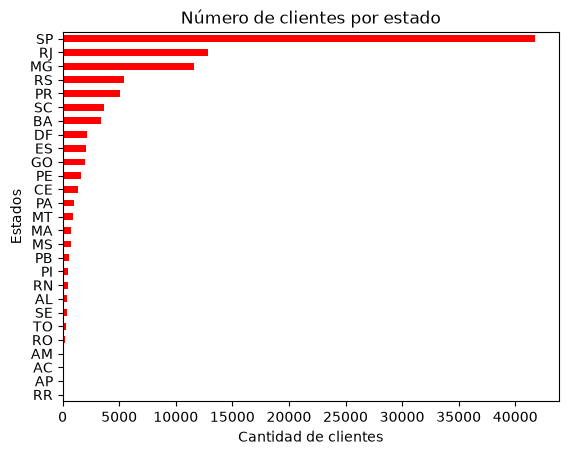

In [5]:
#4
df_4 = customers.groupby("customer_state")["customer_id"].count().sort_values()
df_4.plot(
    kind = "barh",
    title = "Número de clientes por estado",
    xlabel = "Cantidad de clientes",
    ylabel = "Estados",
    color = "red"
)
plt.show()

# 5 Estados principales
Construye un pie chart con los 5 estados que concentran mayor cantidad de clientes.

Agrupa todos los demás estados en una categoría llamada "Otros".

Pregunta: ¿Qué tan concentrada está la base de clientes geográficamente?

La mayoría está en SP.

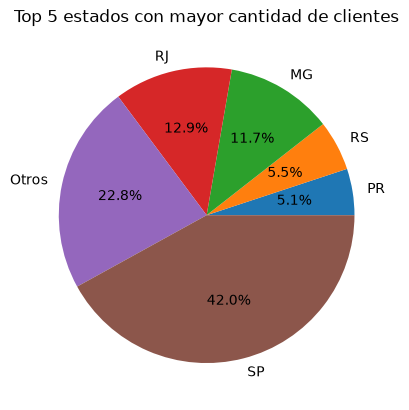

In [6]:
#5
df_5 = customers
top5 = ["SP", "RJ", "MG", "RS", "PR"]
def top(x):
    if x in top5:
        return x
    else:
        return "Otros"

df_5["top5"] = df_5["customer_state"].apply(top)
df_5 = customers.groupby("top5")["customer_id"].count().sort_values(ascending = True)
df_5

df_5.plot(kind = "pie",
          autopct = "%1.1f%%",
          title = "Top 5 estados con mayor cantidad de clientes"
)
plt.show()

# 6 Métodos de pago
Utilizando la tabla de pagos, determina cuántos pagos fueron realizados mediante cada método de pago.

Construye primero una gráfica de barras.

Pregunta: ¿Cuál es el método de pago más utilizado? Tarjeta de crédito.

Después construye un pie chart utilizando exactamente la misma información.

Reflexión:
¿Cuál de las dos gráficas permite comparar mejor los métodos de pago?
La de barras


¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?
La de pastel

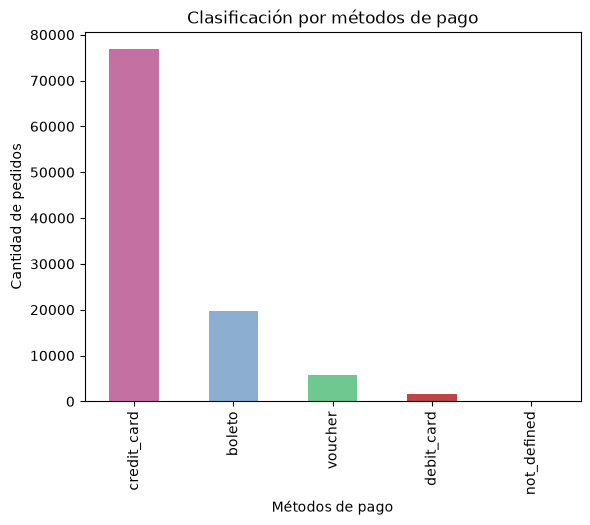

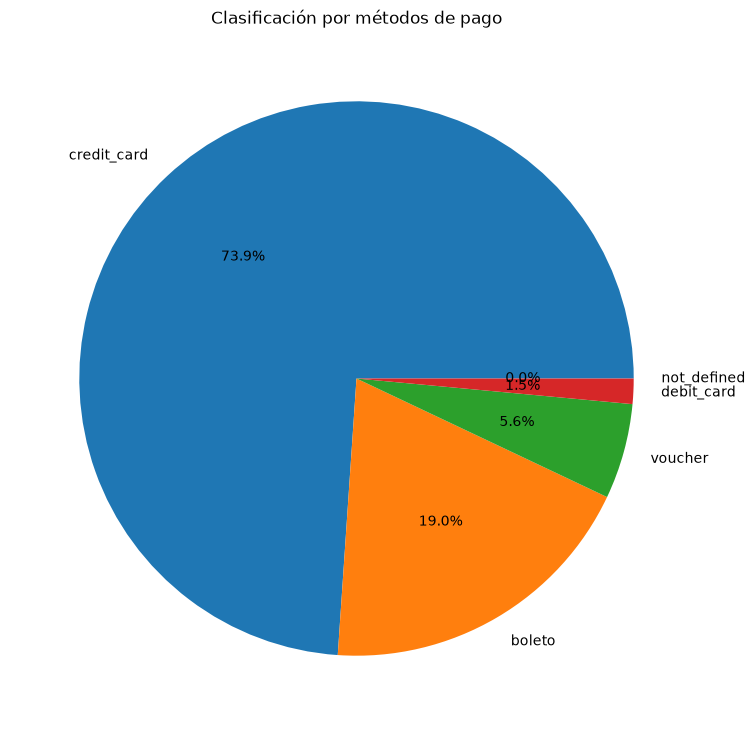

In [7]:
# Gráfica de barras
df_6 = payments
df_6 = df_6.groupby("payment_type")["order_id"].count().sort_values(ascending=False)
df_6.plot(
    kind = "bar",
    title = "Clasificación por métodos de pago",
    xlabel = "Métodos de pago",
    ylabel = "Cantidad de pedidos",
    color = ["#c570a3", "#8baed1", "#6ec890", "#bc4444"]
)

# Pie chart
fig, ax2 = plt.subplots(figsize =(9,9))
df_6.plot(
    kind = "pie",
    title = "Clasificación por métodos de pago",
    autopct = "%1.1f%%"
)

plt.show()

# 7 Número de cuotas
Utilizando la información de pagos, analiza la cantidad de cuotas registrada en payment_installments.

Agrupa las compras por número de cuotas y construye una gráfica de barras.

Pregunta: ¿Qué número de cuotas es el más frecuente? La de 1.

Reto: Muestra únicamente los valores correspondientes de 1 a 10 cuotas.

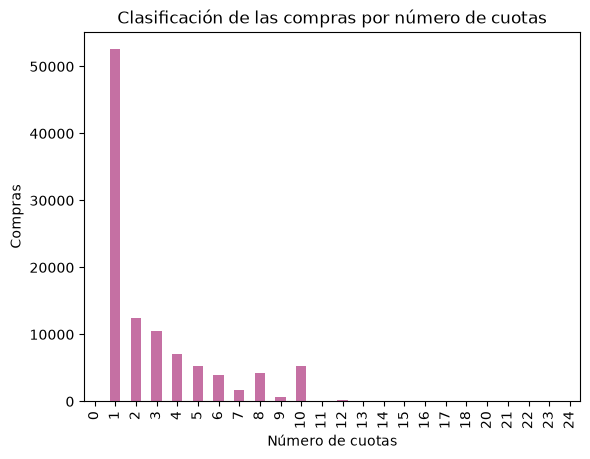

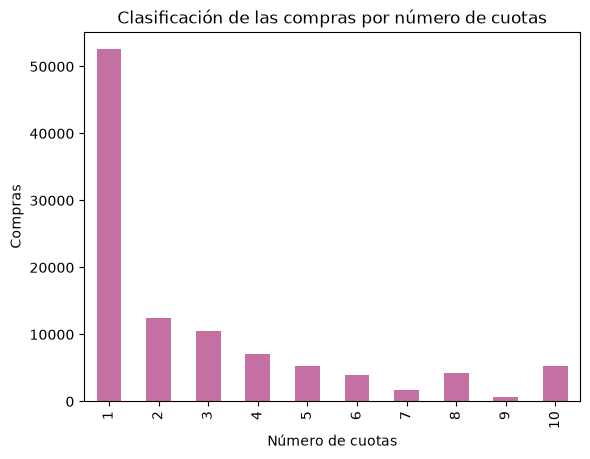

In [8]:
#7
fig, ax = plt.subplots()

df_7 = payments
df_7 = df_7.groupby("payment_installments")["order_id"].count()
df_7.plot(
    kind = "bar",
    xlabel = "Número de cuotas",
    ylabel = "Compras",
    title = "Clasificación de las compras por número de cuotas",
    color = "#c570a3"
)


fig, ax = plt.subplots()
df_71 = payments
df_71 = df_71[df_71["payment_installments"].between(1,10)]
df_71 = df_71.groupby("payment_installments")["order_id"].count()
df_71.plot(
    kind = "bar",
    xlabel = "Número de cuotas",
    ylabel = "Compras",
    title = "Clasificación de las compras por número de cuotas",
    color = "#c570a3"
)

plt.show()

# 8 Comparando visualizaciones
Utiliza la variable payment_type para construir:

1. Una gráfica de barras.
2. Un pie chart.
Las dos gráficas deben representar exactamente los mismos datos.

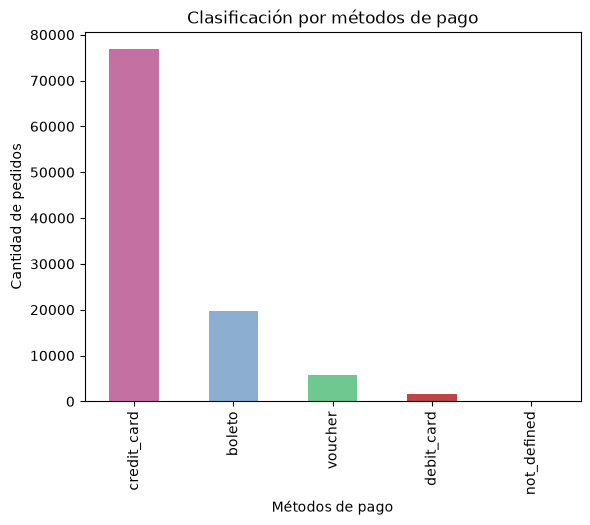

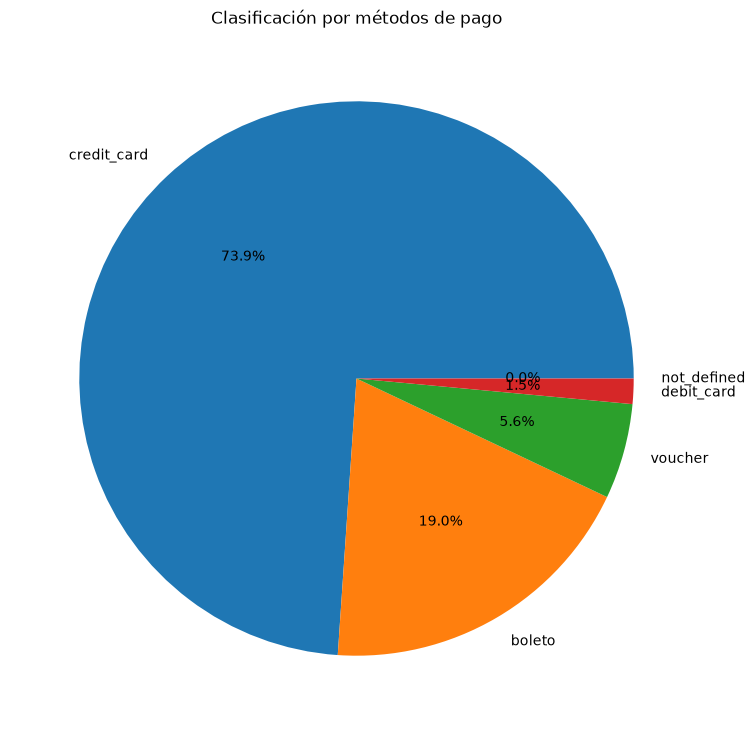

In [9]:
# Gráfica de barras
fig, ax1 = plt.subplots()
df_6 = payments
df_6 = df_6.groupby("payment_type")["order_id"].count().sort_values(ascending=False)
df_6.plot(
    kind = "bar",
    color = ["#c570a3", "#8baed1", "#6ec890", "#bc4444"],
    ax = ax1
)

ax1.set_title("Clasificación por métodos de pago")
ax1.set_xlabel("Métodos de pago")
ax1.set_ylabel("Cantidad de pedidos")

# Pie chart
fig, ax2 = plt.subplots(figsize =(9,9))
df_6.plot(
    kind = "pie",
    title = "Clasificación por métodos de pago",
    autopct = "%1.1f%%",
    ax = ax2
)

ax2.set_title("Clasificación por métodos de pago")

plt.show()